# Data Curation & Preparation

<p>
In this notebook, we are going to explore a dataset about drug consumption. Database contains records for 1885 respondents. For each respondent 12 attributes are known.
    The data set and description can be downloaded from UCI repository under this link: https://archive.ics.uci.edu/dataset/373/drug+consumption+quantified

To avoid having too many cells, the code for the same purpose will be combined in one cell, i.e. each cell will focus on a specific task.

<p>


## 1: Data Preparation


In [36]:
# first, import libraries
import pandas as pd
import numpy as np

In [37]:
# next, import data from the given dataset (for demo, it is different from the data in the UCI link).
df = pd.read_csv('drug_consumption_a1.csv')

# quickly check the data
df.head(5)

,ID,Age,Gender,Education,Country,Ethics,Column7,Column8,Column14,Column15,Column16,Column17
0,1,36,M,PD,0.96,0.13,0.31,-0.58,CL5,CL2,CL0,CL2
1,2,30,F,PhD,0.96,-0.32,-0.68,1.94,CL5,CL2,CL2,CL0
2,3,44,F,PD,0.96,-0.32,-0.47,0.81,CL6,CL0,CL0,CL0
3,4,20,M,Msc,0.96,-0.32,-0.15,-0.81,CL4,CL0,CL0,CL3
4,5,43,M,PhD,0.96,-0.32,0.74,-1.63,CL4,CL1,CL1,CL0


<b> Observation: </b>

<p> The data set contains 12 columns and 999 rows. Some columns have unreadable name like Column7 or Column8. We will need to rename these columns according to the documentation in this site: https://archive.ics.uci.edu/dataset/373/drug+consumption+quantified </p>


#### 1.1 Rename columns


In [38]:
# rename columns to meaningful names
df.rename(columns={'Column7': 'Nscore'}, inplace=True)
df.rename(columns={'Column8': 'Escore'}, inplace=True)
df.rename(columns={'Column14': 'Alcohol'}, inplace=True)
df.rename(columns={'Column15': 'Amphet'}, inplace=True)
df.rename(columns={'Column16': 'Amyl'}, inplace=True)
df.rename(columns={'Column17': 'Benzos'}, inplace=True)

# check the data
df.head(5)

/var/folders/0p/jns3__n92zsdf7xbyc5bmn1c0000gn/T/ipykernel_10019/2029652958.py:2: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.rename(columns={'Column7': 'Nscore'}, inplace=True)
/var/folders/0p/jns3__n92zsdf7xbyc5bmn1c0000gn/T/ipykernel_10019/2029652958.py:3: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.rename(columns={'Column8': 'Escore'}, inplace=True)
/var/folders/0p/jns3__n92zsdf7xbyc5bmn1c0000gn/T/ipykernel_10019/2029652958.py:4: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for 

,ID,Age,Gender,Education,Country,Ethics,Nscore,Escore,Alcohol,Amphet,Amyl,Benzos
0,1,36,M,PD,0.96,0.13,0.31,-0.58,CL5,CL2,CL0,CL2
1,2,30,F,PhD,0.96,-0.32,-0.68,1.94,CL5,CL2,CL2,CL0
2,3,44,F,PD,0.96,-0.32,-0.47,0.81,CL6,CL0,CL0,CL0
3,4,20,M,Msc,0.96,-0.32,-0.15,-0.81,CL4,CL0,CL0,CL3
4,5,43,M,PhD,0.96,-0.32,0.74,-1.63,CL4,CL1,CL1,CL0


In [39]:
# get some simple statistics
df.describe()

,ID,Country,Escore
count,999.000000,997.000000,996.000000
mean,501.669670,0.528405,0.054297
std,289.585979,0.636928,0.941446
min,1.000000,-0.570000,-3.270000
25%,250.500000,-0.100000,-0.580000
50%,502.000000,0.960000,0.000000
75%,752.500000,0.960000,0.640000
max,1002.000000,0.960000,3.010000


In [40]:
# Check the types of loaded columns
df.dtypes

ID             int64
Age              str
Gender           str
Education        str
Country      float64
Ethics           str
Nscore           str
Escore       float64
Alcohol          str
Amphet           str
Amyl             str
Benzos           str
dtype: object

<b> Observation: </b>

<p> Column 'Age' supposed to be numerical are stored as objects. We need to perform some data cleaning tasks for this column .</p>

#### 1.2 Cleaning column 'Age'


In [41]:
# Convert 'Age' to integer, setting invalid values to NaN
df['Age'] = pd.to_numeric(df['Age'], errors='coerce')
df['Age'] = df['Age'].astype('Int64')
df['Age'].dtype

Int64Dtype()

In [42]:
# Find rows where 'Age_numeric' is NaN, indicating invalid data
invalid_age_data = df[df['Age'].isna()]

# Display the invalid data
invalid_age_data

,ID,Age,Gender,Education,Country,Ethics,Nscore,Escore,Alcohol,Amphet,Amyl,Benzos
442,445,<NA>,M,PD,0.96,-0.32,-0.47,0.81,CL5,CL0,CL1,CL0


<b> Observation: </b>

<p> We can see the invalid age at index 445 has a value of "5O" where O is a letter. We can correct this by setting the value to 50. </p>


In [43]:
# correct the invalid data
df.loc[invalid_age_data.index, 'Age'] = 50

# check the data
df['Age'].describe()

count        999.0
mean     37.271271
std       25.05332
min          -56.0
25%           23.0
50%           34.0
75%           45.0
max          289.0
Name: Age, dtype: Float64

<b> Observation: </b>

<p> 
Some data is out of bound, e.g. negative or greater than 100. Some simple fixes can be applied to these records:

- negative age can be set to positive
- age greater than 100 can be divided with remainder (aka modulus) by 100
- age is less than 18 can be removed

</p>


In [44]:
# find negative values of 'Age_numeric'
negative_age_data = df[df['Age'] < 0]
negative_age_data

,ID,Age,Gender,Education,Country,Ethics,Nscore,Escore,Alcohol,Amphet,Amyl,Benzos
250,251,-2,F,Uni,0.96,-0.32,-0.47,0.17,CL5,CL0,CL0,CL0
286,287,-56,M,Uni,0.96,-0.32,0.22,-1.38,CL5,CL0,CL0,CL0


In [45]:
# correct the negative values by multiplying by -1
df.loc[negative_age_data.index, 'Age'] = df.loc[negative_age_data.index, 'Age'] * -1

In [46]:
# find values of 'Age_numeric' that are greater than 100
age_outliers = df[df['Age'] > 100]
age_outliers['Age'].count()

np.int64(14)

In [47]:
# correct the values of 'Age_numeric' that are greater than 100 by taking the modulo 100
df.loc[age_outliers.index, 'Age'] = df.loc[age_outliers.index, 'Age'] % 100

In [48]:
# find value of age that < 18
age_outliers = df[df['Age'] < 18]

# set the value of age that < 18 to na
df.loc[age_outliers.index, 'Age'] = np.nan

In [49]:
# re check the data
df['Age'].describe()

count        995.0
mean      35.38593
std      13.037471
min           18.0
25%           23.0
50%           34.0
75%           45.0
max           94.0
Name: Age, dtype: Float64

<b> Observation: </b>

<p> As a result, the column 'Age' is now converted to integer type and contains valid data.</p>

#### 1.3 Removing invalid data of Nscore and Escore


In [50]:
# convert 'Nscore' to numeric
df['Nscore'] = pd.to_numeric(df['Nscore'], errors='coerce')

# check the Nscore column
df['Nscore'].describe()

count    995.000000
mean       0.249106
std        3.899624
min       -2.760000
25%       -0.680000
50%        0.040000
75%        0.630000
max       79.000000
Name: Nscore, dtype: float64

<b> Observation: </b>

<p> Nscore values should be between -3.46436 and 3.27393. We can remove the invalid data by setting the value to NaN.</p>


In [51]:
# find values of 'Nscore' that are less than -3.46436 and greater than 3.27393
invalid_data = df[(df['Nscore'] < -3.46436) | (df['Nscore'] > 3.27393)]

# set the invalid data to NaN
df.loc[invalid_data.index, 'Nscore'] = np.nan

In [52]:
# check the Escore column
df['Escore'].describe()

count    996.000000
mean       0.054297
std        0.941446
min       -3.270000
25%       -0.580000
50%        0.000000
75%        0.640000
max        3.010000
Name: Escore, dtype: float64

<b> Observation: </b>

<p> Escore values should be between -3.27393 and 3.27393, which seems to be correct in this case, no cleaning is needed. </p>


#### 1.4 Cleaning column 'Education'


In [53]:
# check for missing values
df['Education'].value_counts()

Education
Uni    266
CD     227
Msc    155
PD     141
L21     67
PhD     47
L23     45
B21     19
L22     16
ZQ       2
LX       2
CX       2
KP       1
GT       1
EW       1
TD       1
PN       1
IL       1
DL       1
Name: count, dtype: int64

<b> Observation </b>

<p> 
There are quite a few invalid data in the Education column. We can remove the invalid data by setting the value to NaN. For the values of "PhD", we can replace them with "PD"</p>


In [ ]:
# Remove invalid values from the Education column by replacing anything that is is not in this list with NaN
df['Education'] = df['Education'].apply(lambda x: x if x in ['B16','B21','L16','L17','L18','L21','l22','L23','CD','PD','Uni','MSc','PhD'] else np.nan)

# Replace 'PhD' with 'PD'
df['Education'] = df['Education'].replace('PhD', 'PD')

df['Education'].value_counts()

Education
Uni    266
CD     227
PD     188
L21     67
L23     45
B21     19
Name: count, dtype: int64

In [55]:
# last but not least, remove the id column as it is irrelevant
df.drop(columns='ID', inplace=True)

# one final check before moving on to task 2
df.describe()

/var/folders/0p/jns3__n92zsdf7xbyc5bmn1c0000gn/T/ipykernel_10019/1210761936.py:2: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(columns='ID', inplace=True)


,Age,Country,Nscore,Escore
count,995.0,997.000000,988.000000,996.000000
mean,35.38593,0.528405,-0.000142,0.054297
std,13.037471,0.636928,0.983948,0.941446
min,18.0,-0.570000,-2.760000,-3.270000
25%,23.0,-0.100000,-0.680000,-0.580000
50%,34.0,0.960000,-0.050000,0.000000
75%,45.0,0.960000,0.630000,0.640000
max,94.0,0.960000,3.270000,3.010000


#### 1.5 Cleaning Alcohol and drug consumption columns


In [56]:
# checking Alcohol, Amphet, Amyl and Benzos

value_counts_df = pd.DataFrame({
  'Alcohol': df['Alcohol'].value_counts(),
  'Amphet': df['Amphet'].value_counts(),
  'Amyl': df['Amyl'].value_counts(),
  'Benzos': df['Benzos'].value_counts()
})

value_counts_df

,Alcohol,Amphet,Amyl,Benzos
CL0,18,526.0,637.0,565.0
CL1,23,162.0,144.0,84.0
CL2,43,123.0,132.0,120.0
CL3,97,82.0,53.0,90.0
CL4,138,30.0,15.0,51.0
CL5,393,30.0,12.0,40.0
CL6,283,46.0,6.0,49.0
CL8,2,NaN,NaN,NaN
D8,2,NaN,NaN,NaN


<b> Observation: </b>

<p> All drug consumption columns except the columns 'Alcohol' are correct. For column 'Alcohol', it looks like a typo, we can replace D8 with CL8. </p>


In [57]:
# replace 'D8' with 'CL8' in the Alcohol column
df['Alcohol'] = df['Alcohol'].replace('D8', 'CL8')

## 2: Data Exploration

### Visualisation of columns

In [58]:
# first import libraries
import matplotlib.pyplot as plt

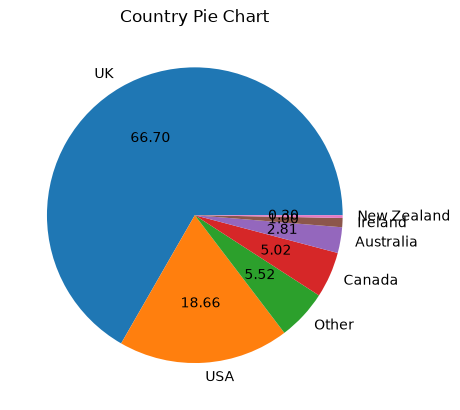

In [59]:
# Nominal columns
nominal_columns = df['Country']

# rename the value to readable values based on the data description available at https://archive.ics.uci.edu/dataset/373/drug+consumption+quantified
nominal_columns = nominal_columns.map({0.96: 'UK', -0.57: 'USA', -0.29: 'Other', 0.25: 'Canada', -0.10: 'Australia', 0.21: 'Ireland', -0.47: 'New Zealand'})

# plot the data using a pie chart with percentages using plt
nominal_columns.value_counts().plot(kind='pie', autopct='%.2f')
plt.title('Country Pie Chart')
plt.show()

<b> Observation: </b>

<p>
Quickly looking at the chart, we can see that the data is not evenly distributed. In fact, the data contains more records from the UK and USA than other countries. Therefore, the data may not be representative for other countries, specially for countries with fewer records.
</p>


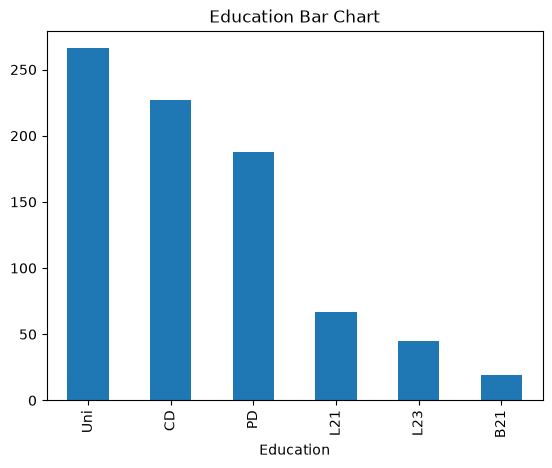

In [60]:
# ordinal data
ordinal_columns = df['Education']

# plot the data using a bar chart
ordinal_columns.value_counts().plot(kind='bar')
plt.title('Education Bar Chart')
plt.show()

<b> Observation: </b>

<p>
The differences between these values are not the same. The chart shows that most respondents have a university or college degree, followed by PhD.
</p>


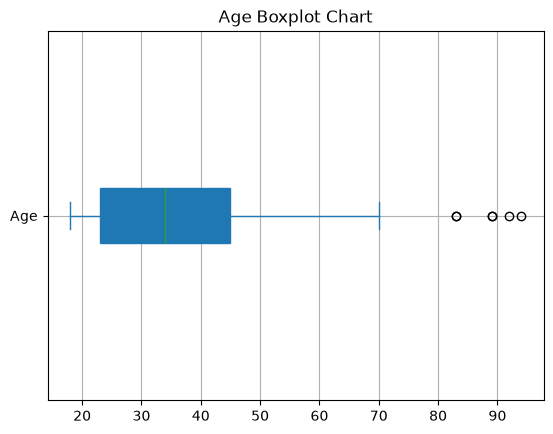

In [61]:
# choose the numerical column
numerical_column = df['Age']

# plot the data using a box plot
numerical_column.plot(kind='box', grid=True, vert=False, patch_artist=True)
plt.title('Age Boxplot Chart')
plt.show()

<b>Observation: </b>

<p>
There is a notable decrease in the number of respondents in the younger age group of 18-20 and the older age group of 45-70. Additionally, there are some outliers in the data, including respondents who exceed 80 years old.
</p>


### Explore the columns


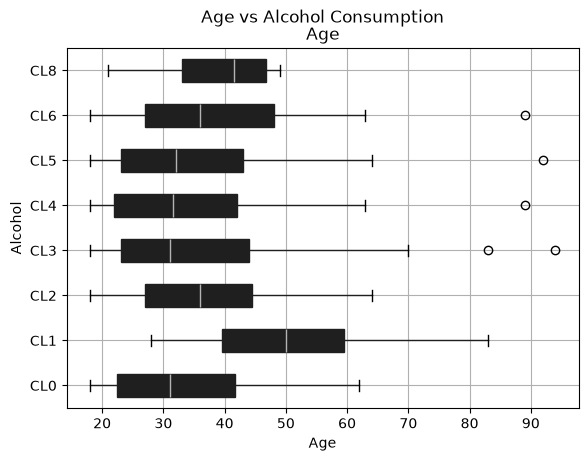

In [62]:
# pair 1: Age vs Alcohol

# choose the columns
age_alcohol_data = df[['Age', 'Alcohol']]

# plot the data using a box plot
age_alcohol_data.boxplot(by='Alcohol', grid=True, vert=False, patch_artist=True)
plt.suptitle('Age vs Alcohol Consumption')
plt.xlabel('Age')
plt.ylabel('Alcohol')
plt.show()


<b> Hypothesis 1: Young people (who are in 20s and 30s) tend to consume more alcohol compared to other groups of age.</b>

To test this hypothesis, I will plot a boxplot between Age and Alcohol columns. Based on this chart, there seems to be evidence to support my hypothesis. By observing frequently drinking groups such as CL6, CL5 and CL4, we can see that the 2nd, median and 3rd quartiles are falling into groups of early 20s and later 30s greater variability compared to older groups. This aligns with the common observation that alcohol consumption tends to peak at a young or middle age, and also tend to decline with age.

</p>


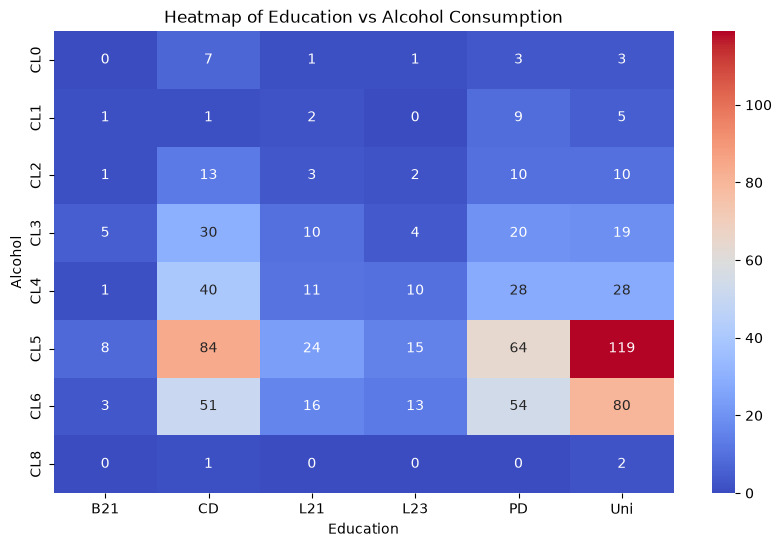

In [63]:
# pair 2: Education vs Alcohol
import seaborn as sns

# Create a contingency table (cross-tabulation) of Education vs Alcohol
education_alcohol_data = pd.crosstab(df['Alcohol'], df['Education'])

# Plot the heatmap
plt.figure(figsize=(10, 6))
sns.heatmap(education_alcohol_data, annot=True, cmap='coolwarm', fmt='d')
plt.title('Heatmap of Education vs Alcohol Consumption')
plt.show()

<b> Hypothesis 2: People with higher education tend to consume less alcohol</b>

<p>
To test this hypothesis, I will plot a heatmap between Education and Alcohol columns. Looking at each of frequently drinking groups of CL6, CL5 and CL4, then compare frequency between education level, we can see that the frequencies are significantly decreased from bachelor (Uni & CD) to postgraduate education (Mcs, PD nd PhD) and This aligns with the common observation that individuals with higher levels of education tend to consume less alcohol likely because higher education has better awareness of health risks and greater focus on long-term goals.
</p>


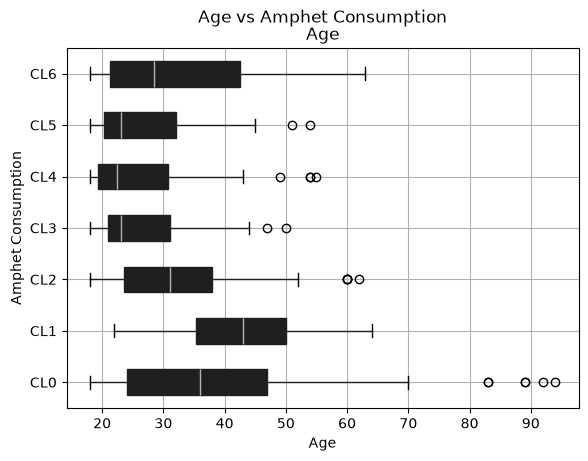

In [64]:
# pair 3: Age vs Amphet

# choose the columns
temp = df[['Age', 'Amphet']]

# plot the data using a box plot
temp.boxplot(by='Amphet', grid=True, vert=False, patch_artist=True)
plt.suptitle('Age vs Amphet Consumption')
plt.xlabel('Age')
plt.ylabel('Amphet Consumption')
plt.show()

<b> Hypothesis 3: Young people who are in their 20s tend to consume drug more then other groups.</b>

<p> To verify this hypothesis, I will plot a boxplot between Age and Amphet columns. Amphet, also known as Amphetamines, is a nervous system stimulant. Younger age groups tend to consume this drug due to various reasons such as peer pressure, desire for stimulation and exploration. Comparing groups CL6, CL5 and CL4, we can see that the 2nd, median and 3rd quartiles are falling into groups of people in their early 20s or 30s compared to other groups. This aligns with the common observation that drug consumption tends to peak a younger age.</p>


<b> Observation: </b>

<p>

- Nscore vs Age: the data is scattered indicates that there is no clear relationship between Nscore and Age.
- Escore vs Age: same as Nscore vs Age, there is no correlation between Escore and Age.
- Nscore vs Escore: the data is quite scattered, but we can see a slight negative correlation between Nscore and Escore. This means that people with higher Nscore tend to have lower Escore and vice versa.
</p>


## 3: Missing Values and Outliers

In [65]:
# reload the data
original_data = pd.read_csv('drug_consumption_a1.csv')

# rename columns for readability
original_data.rename(columns={'Column7': 'Nscore'}, inplace=True)
original_data.rename(columns={'Column8': 'Escore'}, inplace=True)
original_data.rename(columns={'Column14': 'Alcohol'}, inplace=True)
original_data.rename(columns={'Column15': 'Amphet'}, inplace=True)
original_data.rename(columns={'Column16': 'Amyl'}, inplace=True)
original_data.rename(columns={'Column17': 'Benzos'}, inplace=True)

original_data.head(5)

/var/folders/0p/jns3__n92zsdf7xbyc5bmn1c0000gn/T/ipykernel_10019/2493791659.py:5: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  original_data.rename(columns={'Column7': 'Nscore'}, inplace=True)
/var/folders/0p/jns3__n92zsdf7xbyc5bmn1c0000gn/T/ipykernel_10019/2493791659.py:6: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  original_data.rename(columns={'Column8': 'Escore'}, inplace=True)
/var/folders/0p/jns3__n92zsdf7xbyc5bmn1c0000gn/T/ipykernel_10019/2493791659.py:7: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#de

,ID,Age,Gender,Education,Country,Ethics,Nscore,Escore,Alcohol,Amphet,Amyl,Benzos
0,1,36,M,PD,0.96,0.13,0.31,-0.58,CL5,CL2,CL0,CL2
1,2,30,F,PhD,0.96,-0.32,-0.68,1.94,CL5,CL2,CL2,CL0
2,3,44,F,PD,0.96,-0.32,-0.47,0.81,CL6,CL0,CL0,CL0
3,4,20,M,Msc,0.96,-0.32,-0.15,-0.81,CL4,CL0,CL0,CL3
4,5,43,M,PhD,0.96,-0.32,0.74,-1.63,CL4,CL1,CL1,CL0


In [66]:
# copy original data to new variables
fix1 = original_data.copy()
fix2 = original_data.copy()

# find missing values
original_data.isna().sum()


ID           0
Age          0
Gender       0
Education    3
Country      2
Ethics       9
Nscore       2
Escore       3
Alcohol      0
Amphet       0
Amyl         0
Benzos       0
dtype: int64

In [67]:
# create a function for reusability purpose

from typing import Literal

def replace_missing_values(df, column_name, method=Literal['mean', 'median']):
    """
    Replace missing values in a specified column of a DataFrame using the specified method.

    Parameters:
    df (pd.DataFrame): The DataFrame containing the column.
    column_name (str): The name of the column to process.
    method (str): The method to use for replacing missing values ('mean' or 'median').

    Returns:
    pd.DataFrame: The DataFrame with missing values replaced.
    """
    df[column_name] = pd.to_numeric(df[column_name], errors='coerce')
    
    if method == 'mean':
        replacement_value = round(df[column_name].mean(), 2)
    elif method == 'median':
        replacement_value = df[column_name].median()
    else:
        raise ValueError("Method must be 'mean' or 'median'")
    
    df[column_name] = df[column_name].fillna(replacement_value)
    
    print(f"Missing values in column '{column_name}' were replaced with {method} value: {replacement_value}")
    return df

In [68]:
# cleaning 'Ethics' column
fix1 = replace_missing_values(fix1, 'Ethics', method='mean')
fix2 = replace_missing_values(fix2, 'Ethics', method='median')

Missing values in column 'Ethics' were replaced with mean value: -0.22
Missing values in column 'Ethics' were replaced with median value: -0.32


In [69]:
# cleaning 'Nscore' column
fix1 = replace_missing_values(fix1, 'Nscore', method='mean')
fix2 = replace_missing_values(fix2, 'Nscore', method='median')

Missing values in column 'Nscore' were replaced with mean value: 0.25
Missing values in column 'Nscore' were replaced with median value: 0.04


In [70]:
# cleaning 'Escore' column
fix1 = replace_missing_values(fix1, 'Escore', method='mean')
fix2 = replace_missing_values(fix2, 'Escore', method='median')

Missing values in column 'Escore' were replaced with mean value: 0.05
Missing values in column 'Escore' were replaced with median value: 0.0


In [71]:
# cleaning 'Country' column
fix1 = replace_missing_values(fix1, 'Country', method='mean')
fix2 = replace_missing_values(fix2, 'Country', method='median')

Missing values in column 'Country' were replaced with mean value: 0.53
Missing values in column 'Country' were replaced with median value: 0.96


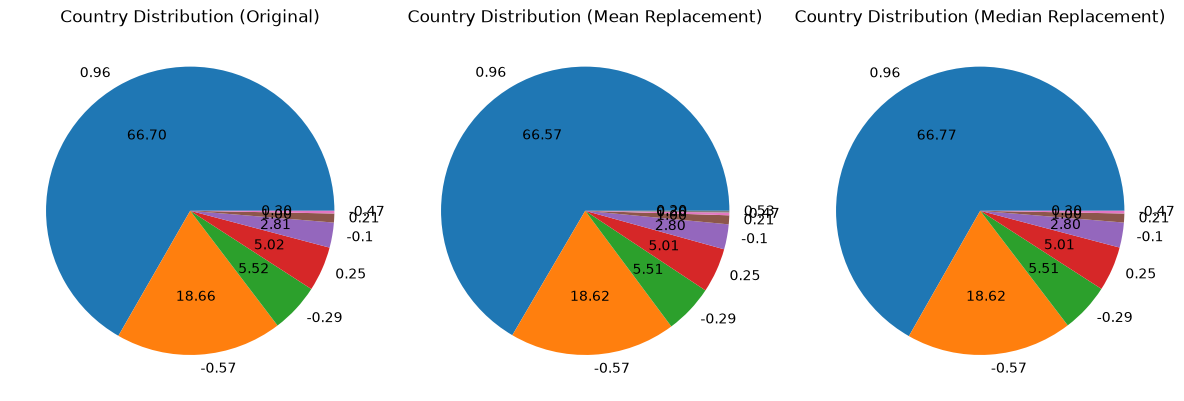

In [72]:
# re-plot the country column after replacing missing data and compare with the original data

# Create subplots
fig, axes = plt.subplots(1, 3, figsize=(12,6))

# Plot the original pie chart
original_data['Country'].value_counts().plot(kind='pie', autopct='%.2f', ax=axes[0])
axes[0].set_title('Country Distribution (Original)')

# Plot the data after mean replacement
fix1['Country'].value_counts().plot(kind='pie', autopct='%.2f', ax=axes[1])
axes[1].set_title('Country Distribution (Mean Replacement)')

# Plot the data after median replacement
fix2['Country'].value_counts().plot(kind='pie', autopct='%.2f', ax=axes[2])
axes[2].set_title('Country Distribution (Median Replacement)')

plt.tight_layout()

# Show the plots
plt.show()

<b> Observation: </b>

<p>

- Comparing the mean replacement graph to the original one, we can see that the mean replacement introduced a new value (mean) which does not fall into any countries. The approach is not suitable for nominal or ordinal data.
- Comparing the median replacement graph to the original one, we can see that the median replacement adds more entries to the 0.96 group (UK). This can be easily explained by the fact that the median value is the value of the most frequent country in the data set.

</p>


In [73]:
# finally, save the cleaned data to a new csv files
fix1.to_csv('file1.csv', index=False)
fix2.to_csv('file2.csv', index=False)

### 3. Discussion

<b> Do outliers affect standard deviation? </b>


<b> When should an outlier not be removed? </b>

<b> How do you detect them? </b>


## References

- Žitnik, Slavko, and Erik Štrumbelj (2024, October 20). Chapter 7 Summarizing data - visualization | Introduction to data science. [fri-datascience.github.io/course_ids/handbook/summarize2.html#boxplot](https://fri-datascience.github.io/course_ids/handbook/summarize2.html#boxplot).
